# Predicting Amsterdam Airbnb prices with location data

**Research question:** can location features (neighbourhood, distance to the city centre) improve nightly price predictions for Amsterdam Airbnb listings, compared with basic listing features?

**Data:** https://insideairbnb.com/get-the-data/

## 0. Setup

In [2]:
# Import required libraries
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geopandas as gpd
import shapely      
import plotly.express as px  
import plotly.io as pio     

from xgboost import XGBRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

SEED = 42

DATA_DIR = Path("data")
LISTINGS_PATH = DATA_DIR / "listings.csv"
GEOJSON_PATH = DATA_DIR / "neighbourhoods.geojson"
CLEAN_PATH = DATA_DIR / "listings_clean.csv"

CRS_LONLAT = "EPSG:4326"        # longitude / latitude, in degrees
CRS_DUTCH = "EPSG:28992"        # Dutch grid, in metres
DAM_SQUARE = (4.8926, 52.3731)  # (longitude, latitude)

pd.set_option("display.max_columns", 50)

pio.renderers.default = "plotly_mimetype+notebook_connected"

## 1. Load and explore the data

### 1.1 Load the listings

In [3]:
# load dataset into a DataFrame
listings_raw = pd.read_csv(LISTINGS_PATH)

listings = listings_raw.copy()

print(listings.shape)
listings.head()

(10612, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,...,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,28871,https://www.airbnb.com/rooms/28871,20260916052246,2026-09-17,NaN,Comfortable double room,Basic bedroom in the center of Amsterdam.,NaN,https://a0.muscache.com/pictures/160889/362340...,124245,https://www.airbnb.com/users/show/124245,1462510208428038971,https://www.airbnb.com/users/profile/146251020...,Edwin,NaN,16,4,15,8,"Amsterdam, The Netherlands",Hi,NaN,NaN,NaN,t,...,49,2026-09-17,815,83,3,1,95,255,24735.0,2010-08-22,2026-08-29,4.86,4.89,4.84,4.94,4.94,4.93,4.83,0363 607B EA74 0BD8 2F6F,NaN,2,0,2,0,4.16
1,29051,https://www.airbnb.com/rooms/29051,20260916052246,2026-09-17,previous scrape,Comfortable single / double room,This room can also be rented as a single or a ...,NaN,https://a0.muscache.com/pictures/162009/bd6be2...,124245,https://www.airbnb.com/users/show/124245,1462510208428038971,https://www.airbnb.com/users/profile/146251020...,Edwin,NaN,16,4,15,8,"Amsterdam, The Netherlands",Hi,NaN,NaN,NaN,t,...,0,2026-09-17,929,77,3,0,85,255,NaN,2011-03-16,2026-08-29,4.82,4.89,4.83,4.93,4.93,4.88,4.79,0363 607B EA74 0BD8 2F6F,NaN,2,0,2,0,4.92
2,44391,https://www.airbnb.com/rooms/44391,20260916052246,2026-09-17,previous scrape,Quiet 2-bedroom Amsterdam city centre apartment,Guests greatly appreciate the unique location ...,NaN,https://a0.muscache.com/pictures/97741545/3900...,194779,https://www.airbnb.com/users/show/194779,1462512336903650281,https://www.airbnb.com/users/profile/146251233...,Jan,NaN,16,1,11,2,"Amsterdam, Netherlands",Love to travel while hosting and to host while...,NaN,NaN,NaN,f,...,0,2026-09-17,42,0,0,0,0,0,NaN,2010-09-16,2022-08-20,4.71,4.68,4.49,4.95,4.90,4.68,4.50,0363 E76E F06A C1DD 172C,NaN,1,1,0,0,0.22
3,48373,https://www.airbnb.com/rooms/48373,20260916052246,2026-09-17,previous scrape,Cozy family home in Amsterdam South,Charming modern apartment in the quiet and gre...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,220434,https://www.airbnb.com/users/show/220434,1462513002935125765,https://www.airbnb.com/users/profile/146251300...,Vesna & Misha,NaN,16,0,15,8,"Amsterdam, Netherlands",NaN,NaN,NaN,NaN,f,...,0,2026-09-17,5,0,0,0,0,0,NaN,2023-07-21,2024-04-28,5.00,5.00,5.00,5.00,5.00,4.60,5.00,0363 4A2B A6AD 0196 F684,NaN,1,1,0,0,0.13
4,49552,https://www.airbnb.com/rooms/49552,20260916052246,2026-09-17,NaN,Multatuli Luxury Guest Suite in top location,Stylish & spacious 60m2 guest suite in Amsterd...,NaN,https://a0.muscache.com/pictures/a6d6d2ee-3196...,225987,https://www.airbnb.com/users/show/225987,1462513152257851081,https://www.airbnb.com/users/profile/146251315...,Joanna & MP,NaN,16,0,15,8,"Amsterdam, The Netherlands",Joanna is from London and MP is from Amsterdam...,NaN,NaN,NaN,t,...,270,2026-09-17,667,56,4,68,54,255,108194.0,2010-10-29,2026-09-07,4.94,4.93,4.94,4.96,4.97,4.98,4.79,0363 576A D827 5085 6B83,NaN,1,1,0,0,3.45


In [4]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10612 entries, 0 to 10611
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            10612 non-null  int64  
 1   listing_url                                   10612 non-null  object 
 2   scrape_id                                     10612 non-null  int64  
 3   last_scraped                                  10612 non-null  object 
 4   source                                        4972 non-null   object 
 5   name                                          10612 non-null  object 
 6   description                                   10608 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   10612 non-null  object 
 9   host_id                                       10612 non-null 

The datasert has 90 columns. Many are of no use for a price model (e.g URLs), and some columns are completely empty.

In [5]:
# columns with no values at all
empty_cols = listings.columns[listings.isna().all()]
print(len(empty_cols), "completely empty columns:")
print(list(empty_cols))

14 completely empty columns:
['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'instant_bookable']


In [6]:
keep_cols = [
    "id",
    "price",
    "room_type", "property_type", "accommodates", "bedrooms", "beds",
    "bathrooms_text", "amenities", "minimum_nights", "availability_365",
    "number_of_reviews", "reviews_per_month", "last_review", "review_scores_rating",
    "host_is_superhost", "calculated_host_listings_count", "hosts_time_as_host_years",
    "neighbourhood_cleansed", "latitude", "longitude",
]
listings = listings[keep_cols].copy()
listings.head()

,id,price,room_type,property_type,accommodates,bedrooms,beds,bathrooms_text,amenities,minimum_nights,availability_365,number_of_reviews,reviews_per_month,last_review,review_scores_rating,host_is_superhost,calculated_host_listings_count,hosts_time_as_host_years,neighbourhood_cleansed,latitude,longitude
0,28871,$97.00,Private room,Private room in rental unit,2,1.0,1.0,1 shared bath,"[""Bed linens"", ""Hair dryer"", ""Iron"", ""Heating""...",2.0,49,815,4.16,2026-08-29,4.86,t,2,15,Centrum-West,52.36775,4.89092
1,29051,NaN,Private room,Private room in condo,2,1.0,1.0,1 shared bath,"[""Bed linens"", ""Shower gel"", ""Hair dryer"", ""Ir...",2.0,0,929,4.92,2026-08-29,4.82,t,2,15,Centrum-Oost,52.36584,4.89111
2,44391,NaN,Entire home/apt,Entire rental unit,4,2.0,2.0,1.5 baths,"[""Bed linens"", ""Smoke alarm"", ""Cooking basics""...",3.0,0,42,0.22,2022-08-20,4.71,f,1,11,Centrum-Oost,52.37168,4.91471
3,48373,NaN,Entire home/apt,Entire rental unit,4,2.0,2.0,1.5 baths,"[""Bed linens"", ""Long term stays allowed"", ""Smo...",3.0,0,5,0.13,2024-04-28,5.00,f,1,15,Buitenveldert - Zuidas,52.32781,4.87680
4,49552,$424.29,Entire home/apt,Entire guest suite,3,2.0,2.0,1 bath,"[""Bed linens"", ""Smoke alarm"", ""Mini fridge"", ""...",1.0,270,667,3.45,2026-09-07,4.94,t,1,15,Centrum-West,52.38028,4.89089


In [7]:
#clean price data

listings["price"] = (
    listings["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)
print(listings["price"].dropna().head(3).tolist())

[97.0, 424.29, 225.0]


/var/folders/pr/w8zlwczs7471f6bbm6q9mw8c0000gn/T/ipykernel_90438/2149262260.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  listings["price"] = (


### 1.2 Numeric data

In [8]:
# numeric data
df_num = listings.select_dtypes("number").drop(columns="id")
df_num.describe().T

,count,mean,std,min,25%,50%,75%,max
price,6039.0,345.064526,337.987873,29.00000,202.000000,285.250000,407.000000,11681.00000
accommodates,10612.0,2.929325,1.266601,1.00000,2.000000,2.000000,4.000000,16.00000
bedrooms,10583.0,1.531796,0.880448,0.00000,1.000000,1.000000,2.000000,17.00000
beds,10227.0,1.830644,1.358225,1.00000,1.000000,1.000000,2.000000,33.00000
minimum_nights,10344.0,3.792827,15.747927,1.00000,2.000000,2.000000,3.000000,800.00000
availability_365,10612.0,93.621466,123.624953,0.00000,0.000000,14.000000,178.250000,365.00000
number_of_reviews,10612.0,53.894365,147.699524,0.00000,3.000000,11.000000,35.000000,5732.00000
reviews_per_month,9610.0,1.091877,2.565403,0.01000,0.190000,0.390000,0.930000,90.08000
review_scores_rating,9610.0,4.848943,0.247408,1.00000,4.800000,4.920000,5.000000,5.00000
calculated_host_listings_count,10612.0,1.830758,2.693007,1.00000,1.000000,1.000000,1.000000,24.00000


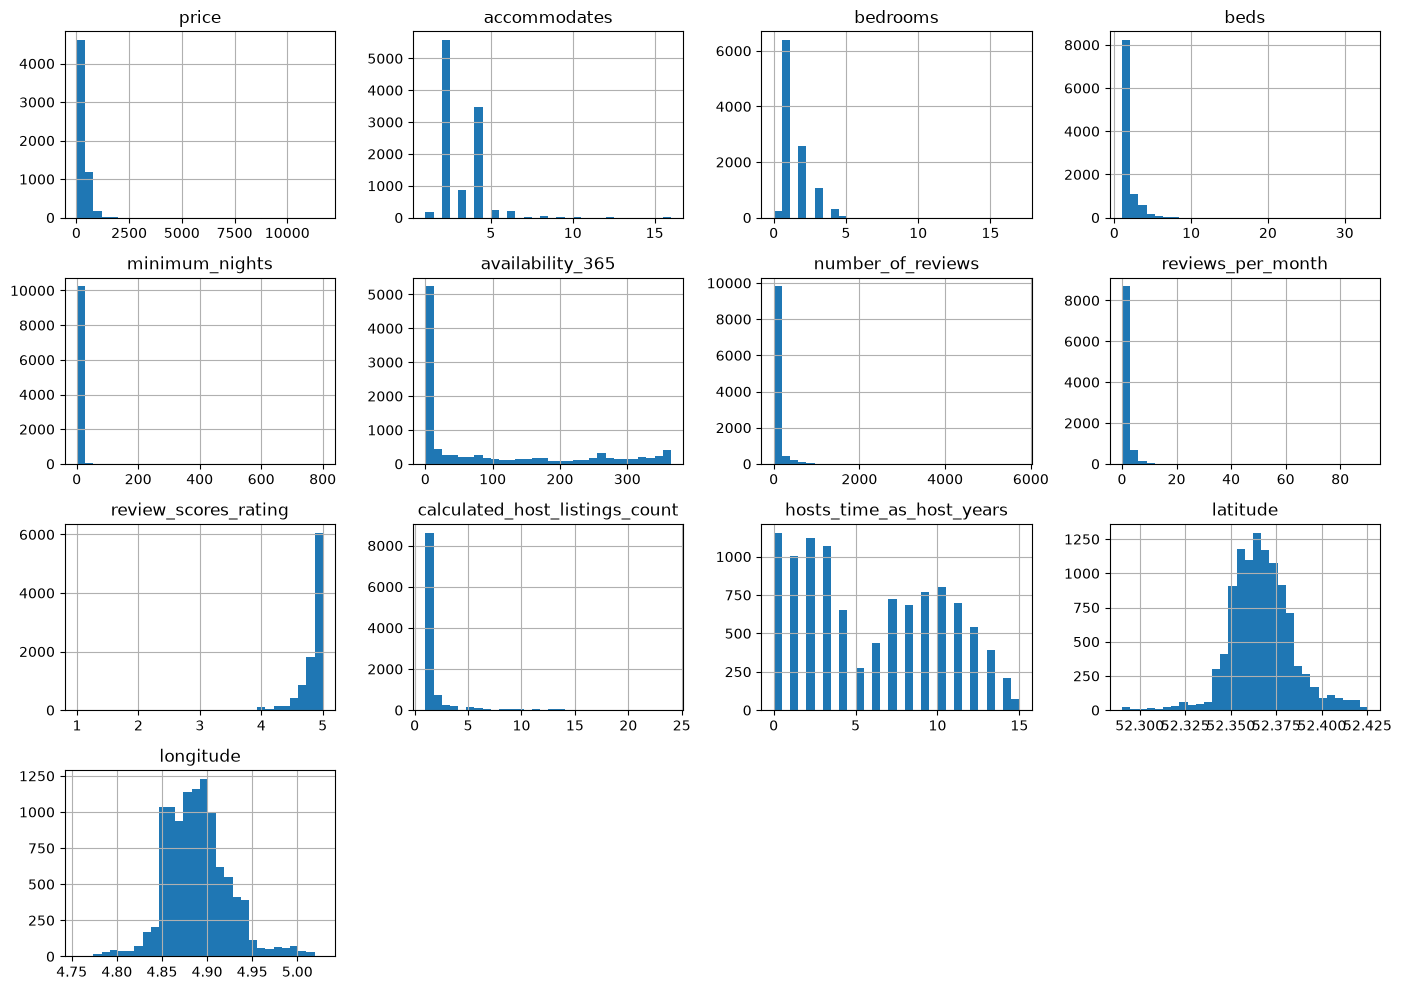

In [9]:
# one histogram per numeric column
df_num.hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

Most columns are right-skewed. `price` is the most extreme. One bar holds almost all listings, because the maximum is above 11,000 euros.

A log scale shows the shape of the price better.

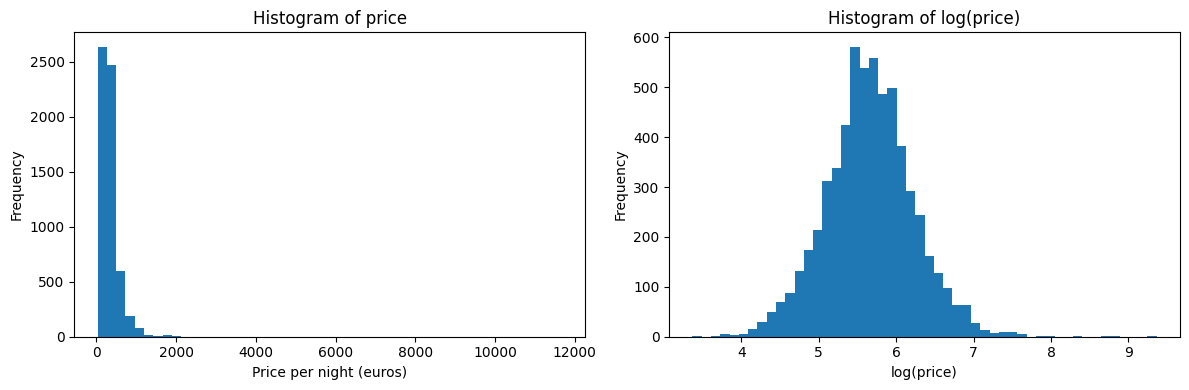

In [9]:
#log transformation

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(listings["price"].dropna(), bins=50)
axes[0].set_title("Histogram of price")
axes[0].set_xlabel("Price per night (euros)")
axes[0].set_ylabel("Frequency")

axes[1].hist(np.log(listings["price"].dropna()), bins=50)
axes[1].set_title("Histogram of log(price)")
axes[1].set_xlabel("log(price)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 1.3 Categorical data

In [10]:
# categorical data
df_cat = listings.select_dtypes(exclude="number")
df_cat.describe().T

,count,unique,top,freq
room_type,10612,4,Entire home/apt,8579
property_type,10612,59,Entire rental unit,4532
bathrooms_text,10604,23,1 bath,5546
amenities,10612,10048,"[""Kitchen"", ""TV"", ""Smoke alarm"", ""Wifi"", ""Wash...",19
last_review,9610,1535,2026-09-13,336
host_is_superhost,10612,2,f,8890
neighbourhood_cleansed,10612,22,De Baarsjes - Oud-West,1836


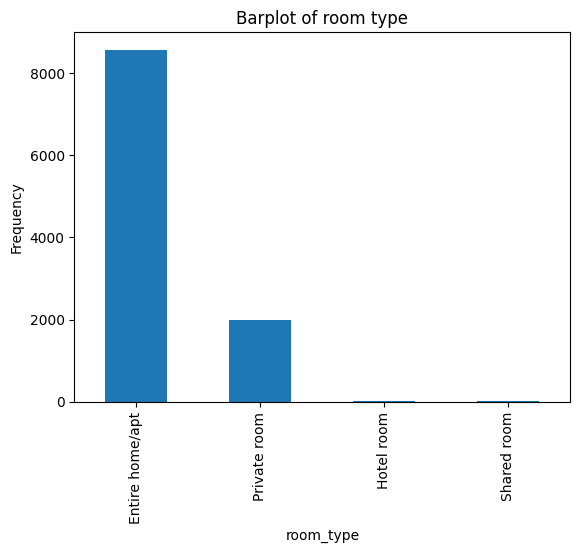

In [11]:
# visualize room type
listings["room_type"].value_counts().plot.bar()
plt.xlabel("room_type")
plt.ylabel("Frequency")
plt.title("Barplot of room type")
plt.show()

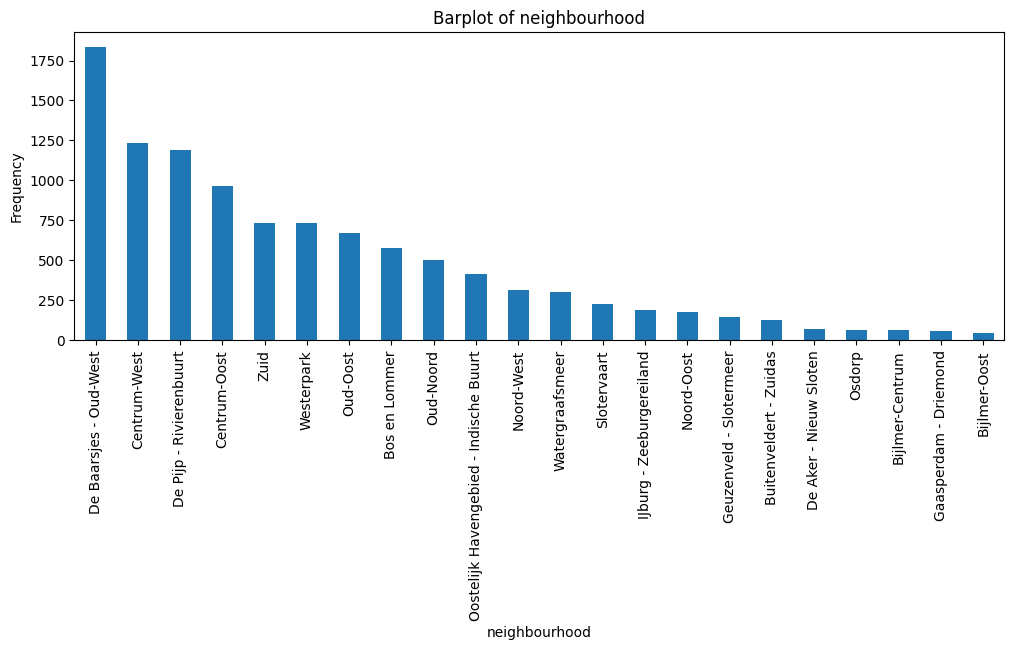

In [12]:
# visualize neighbourhood
listings["neighbourhood_cleansed"].value_counts().plot.bar(figsize=(12, 4))
plt.xlabel("neighbourhood")
plt.ylabel("Frequency")
plt.title("Barplot of neighbourhood")
plt.show()

In [13]:
# property type has many categories, most of them rare
print(listings["property_type"].nunique(), "different property types")
listings["property_type"].value_counts().head(10)

59 different property types


property_type
Entire rental unit                   4532
Entire condo                         1819
Entire home                          1189
Room in hotel                         516
Private room in rental unit           369
Private room in bed and breakfast     298
Entire loft                           247
Entire townhouse                      224
Houseboat                             193
Private room in condo                 189
Name: count, dtype: int64

### 1.4 Price against other columns

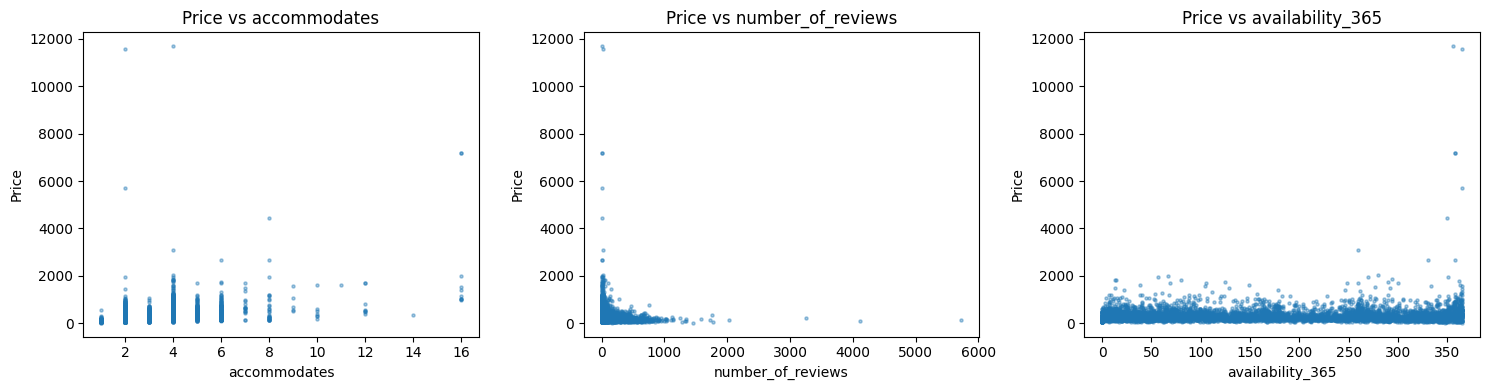

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["accommodates", "number_of_reviews", "availability_365"]):
    ax.scatter(listings[col], listings["price"], s=5, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel("Price")
    ax.set_title("Price vs " + col)

plt.tight_layout()
plt.show()

Outliers make it hard to intepret, need to be handled

In [15]:
listings.groupby("room_type")["price"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
room_type,,,
Entire home/apt,4320,401.1,332.0
Hotel room,23,226.7,190.0
Private room,1674,205.3,176.1
Shared room,22,93.2,63.5


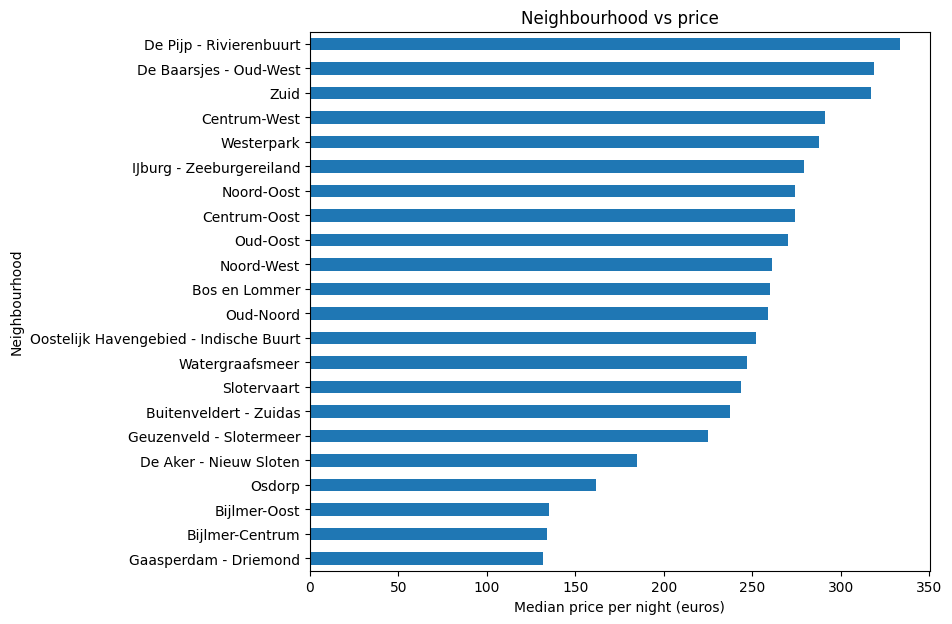

In [16]:
listings.groupby("neighbourhood_cleansed")["price"].median().sort_values().plot.barh(figsize=(8, 7))
plt.xlabel("Median price per night (euros)")
plt.ylabel("Neighbourhood")
plt.title("Neighbourhood vs price")
plt.show()

- Entire homes cost about twice as much as private rooms.
- The median price differs a lot between neighbourhoods: from about 130 euros in the south-east to about 330 euros in De Pijp.

### 1.5 Load the neighbourhood polygons (GeoJSON)

The second file is a GeoJSON file. It holds the **shape** of each neighbourhood, not just its name.

In [17]:
neighbourhoods_raw = gpd.read_file(GEOJSON_PATH) #holds the shape of each neighbourhood

neighbourhoods_raw.head()

,neighbourhood,neighbourhood_group,geometry
0,Bijlmer-Oost,None,"MULTIPOLYGON Z (((4.99167 52.32444 0, 4.99176 ..."
1,Oud-Noord,None,"MULTIPOLYGON Z (((4.95242 52.38983 0, 4.95242 ..."
2,Noord-Oost,None,"MULTIPOLYGON Z (((5.07916 52.38865 0, 5.0671 5..."
3,Noord-West,None,"MULTIPOLYGON Z (((4.93072 52.41161 0, 4.93051 ..."
4,IJburg - Zeeburgereiland,None,"MULTIPOLYGON Z (((5.03906 52.35458 0, 5.02022 ..."


In [19]:
# names in the GeoJSON are the same 22 names as in the listings
set(neighbourhoods_raw["neighbourhood"]) == set(listings["neighbourhood_cleansed"])

True

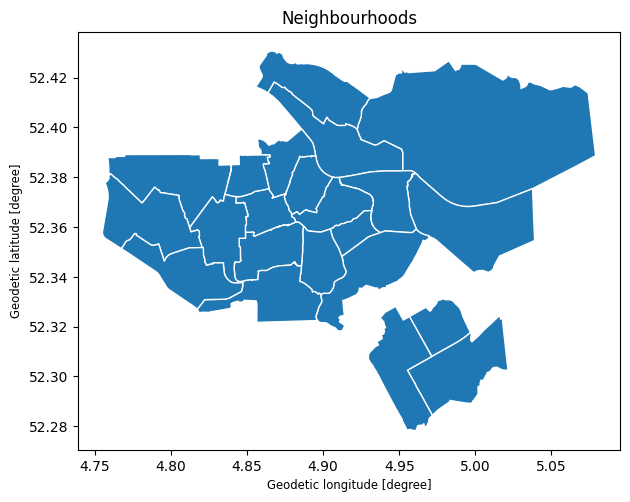

In [19]:
neighbourhoods_raw.plot(edgecolor="white", figsize=(7, 7))
plt.title("Neighbourhoods")
plt.show()

## 2. Cleanse and transform the data

### 2.1 Missing values

In [20]:
listings.isnull().sum()

id                                   0
price                             4573
room_type                            0
property_type                        0
accommodates                         0
bedrooms                            29
beds                               385
bathrooms_text                       8
amenities                            0
minimum_nights                     268
availability_365                     0
number_of_reviews                    0
reviews_per_month                 1002
last_review                       1002
review_scores_rating              1002
host_is_superhost                    0
calculated_host_listings_count       0
hosts_time_as_host_years             0
neighbourhood_cleansed               0
latitude                             0
longitude                            0
dtype: int64

### 2.2 Missing prices

About 43% of the listings have no price.

In [22]:
missing_price = listings["price"].isna()
print("Share of listings without a price:", round(missing_price.mean(), 3))

# compare with availability: is the listing bookable on 0 days of the next year?
pd.crosstab(
    missing_price.rename("price is missing"),
    (listings["availability_365"] == 0).rename("availability_365 is 0"),
    normalize="index",
).round(3)

Share of listings without a price: 0.431


availability_365 is 0,False,True
price is missing,,
False,0.957,0.043
True,0.082,0.918


About 92% of the listings without a price cannot be booked on any day of the next year. For listings with a price this is only about 4%. Hence, a listing without a price is mostly an inactive listing.

In [21]:
listings = listings[listings["price"].notna()].copy() #drop NA prices
print(listings.shape)

(6039, 21)


### 2.3 Reviews

`last_review`, `reviews_per_month` and `review_scores_rating` are missing for listings that have no reviews yet.

- `last_review` becomes a flag `has_reviews`: 1 if there is a review, 0 if not.
- `reviews_per_month` becomes 0.
- `review_scores_rating` stays missing. (no obvious handling, xgboost to handle)

In [22]:
listings["has_reviews"] = listings["last_review"].notna().astype(int)
listings = listings.drop(columns="last_review")

listings["reviews_per_month"] = listings["reviews_per_month"].fillna(0)

listings[["has_reviews", "reviews_per_month", "review_scores_rating"]].describe().T

/var/folders/pr/w8zlwczs7471f6bbm6q9mw8c0000gn/T/ipykernel_90438/3791713538.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  listings["has_reviews"] = listings["last_review"].notna().astype(int)
/var/folders/pr/w8zlwczs7471f6bbm6q9mw8c000

,count,mean,std,min,25%,50%,75%,max
has_reviews,6039.0,0.900977,0.298718,0.0,1.00,1.00,1.000,1.00
reviews_per_month,6039.0,1.477023,3.143777,0.0,0.22,0.54,1.615,90.08
review_scores_rating,5441.0,4.833134,0.258881,1.0,4.77,4.91,5.000,5.00


### 2.4 Text columns to numbers


In [23]:
listings["bathrooms_text"].value_counts().head(12)

bathrooms_text
1 bath              2918
1.5 baths           1040
1 private bath      1011
2 baths              350
1 shared bath        259
2.5 baths            111
1.5 shared baths     109
0 shared baths        62
3 baths               57
0 baths               33
Half-bath             20
3.5 baths             16
Name: count, dtype: int64

In [24]:
#digits, then maybe a dot and more digits
listings["bathrooms"] = listings["bathrooms_text"].str.extract(r"(\d+\.?\d*)")[0].astype(float)

# half = 0.5
is_half = listings["bathrooms_text"].str.contains("half", case=False, na=False)
listings.loc[is_half, "bathrooms"] = 0.5

# 1 if the bathroom is shared, else 0
listings["bathroom_shared"] = listings["bathrooms_text"].str.contains("shared", case=False, na=False).astype(int)

listings[["bathrooms_text", "bathrooms", "bathroom_shared"]].drop_duplicates().sort_values("bathrooms").head(12)

/var/folders/pr/w8zlwczs7471f6bbm6q9mw8c0000gn/T/ipykernel_90438/2285044561.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  listings["bathrooms"] = listings["bathrooms_text"].str.extract(r"(\d+\.?\d*)")[0].astype(float)
/var/folders/pr/w

,bathrooms_text,bathrooms,bathroom_shared
816,0 baths,0.0,0
331,0 shared baths,0.0,1
696,Half-bath,0.5,0
969,Private half-bath,0.5,0
5692,Shared half-bath,0.5,1
0,1 shared bath,1.0,1
10,1 private bath,1.0,0
4,1 bath,1.0,0
53,1.5 shared baths,1.5,1
8,1.5 baths,1.5,0


In [27]:
listings = listings.drop(columns="bathrooms_text")

In [25]:
print(listings["amenities"].iloc[0][:100], "...")
#convert raw string into list
listings["amenities_count"] = listings["amenities"].apply(json.loads).apply(len)
listings = listings.drop(columns="amenities")

listings["amenities_count"].describe()

["Bed linens", "Hair dryer", "Iron", "Heating", "Smoke alarm", "Private entrance", "Cleaning product ...


/var/folders/pr/w8zlwczs7471f6bbm6q9mw8c0000gn/T/ipykernel_90438/376715016.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  listings["amenities_count"] = listings["amenities"].apply(json.loads).apply(len)


count    6039.000000
mean       31.973340
std        15.192803
min         0.000000
25%        21.000000
50%        31.000000
75%        43.000000
max        99.000000
Name: amenities_count, dtype: float64

I only used the count. Some single amenities, such as "Waterfront" or "Canal view", say something about the location, which may blur the line between the basic features and the location features.



In [27]:
print(listings["host_is_superhost"].value_counts(dropna=False))
#convert to binary
listings["host_is_superhost"] = (listings["host_is_superhost"] == "t").astype(int)

host_is_superhost
f    4622
t    1417
Name: count, dtype: int64


/var/folders/pr/w8zlwczs7471f6bbm6q9mw8c0000gn/T/ipykernel_90438/464241142.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  listings["host_is_superhost"] = (listings["host_is_superhost"] == "t").astype(int)


### 2.5 Rare property types

`property_type` has many categories, and most have only a few listings. A category with one or two listings is not useful for a model. I grouped every type with fewer than 30 listings into `Other`.

In [28]:
type_counts = listings["property_type"].value_counts()
rare_types = type_counts[type_counts < 30].index
print(len(rare_types), "rare types, with", type_counts[rare_types].sum(), "listings in total")

listings.loc[listings["property_type"].isin(rare_types), "property_type"] = "Other"
listings["property_type"].value_counts()

37 rare types, with 192 listings in total


property_type
Entire rental unit                   2257
Entire condo                          824
Entire home                           611
Room in hotel                         488
Private room in rental unit           272
Private room in bed and breakfast     250
Other                                 192
Private room in condo                 155
Entire loft                           128
Houseboat                             114
Private room in home                  104
Entire townhouse                       92
Boat                                   81
Entire serviced apartment              80
Room in boutique hotel                 69
Private room in townhouse              66
Private room in houseboat              59
Private room in guest suite            57
Entire guest suite                     37
Private room in guesthouse             35
Private room in boat                   35
Entire guesthouse                      33
Name: count, dtype: int64

### 2.6 Outliers in price


Removing outliers from log(price) instead of price, as high prices may be due to luxury homes instead of itself being an anomaly.


In [29]:
print("Skew of price:     ", round(listings["price"].skew(), 2))
print("Skew of log(price):", round(np.log(listings["price"]).skew(), 2))

log_price = np.log(listings["price"])
Q1 = log_price.quantile(0.25)
Q3 = log_price.quantile(0.75)
IQR = Q3 - Q1

# np.exp turns the limits back into euros
minimum = np.exp(Q1 - 1.5 * IQR)
maximum = np.exp(Q3 + 1.5 * IQR)

print("Outliers are below {0:.0f} euros or above {1:.0f} euros".format(minimum, maximum))
print("Listings below the minimum:", (listings["price"] < minimum).sum())
print("Listings above the maximum:", (listings["price"] > maximum).sum())

Skew of price:      16.84
Skew of log(price): 0.23
Outliers are below 71 euros or above 1164 euros
Listings below the minimum: 46
Listings above the maximum: 63


In [33]:
# The cheapest listings
listings[listings["price"] < minimum].sort_values("price")[
    ["price", "room_type", "property_type", "accommodates"]].head(8)

,price,room_type,property_type,accommodates
4925,29.0,Shared room,Other,1
7708,38.0,Shared room,Other,1
6516,39.9,Private room,Private room in bed and breakfast,1
3761,42.0,Shared room,Other,1
7607,43.0,Shared room,Other,1
2990,44.0,Shared room,Other,1
8584,45.0,Shared room,Other,1
5692,45.0,Private room,Private room in townhouse,1


In [34]:
# The most expensive listings
listings[listings["price"] > maximum].sort_values("price", ascending=False)[
    ["price", "room_type", "property_type", "accommodates", "bedrooms"]].head(8)

,price,room_type,property_type,accommodates,bedrooms
9306,11681.0,Entire home/apt,Entire home,4,2.0
245,11581.2,Entire home/apt,Entire rental unit,2,1.0
4681,7200.0,Entire home/apt,Boat,16,7.0
4365,7200.0,Entire home/apt,Boat,16,17.0
3402,5706.0,Entire home/apt,Entire rental unit,2,1.0
6116,4439.6,Entire home/apt,Entire home,8,4.0
1455,3104.0,Entire home/apt,Houseboat,4,3.0
5754,2678.0,Entire home/apt,Boat,8,3.0


I kept low prices as they are beds in shared rooms and single private rooms, which seems like realistic cheap listings.

I removed high prices as prices of several thousand euros per night for a normal flat or boat are not normal nightly prices. They are more likely placeholder prices or event prices. I removed the listings above the upper limit (about 1% of the data).

Because the price is so skewed, the model will also predict **log(price)**. I will turn every prediction back into euros before I measure the error.

In [30]:
listings = listings[listings["price"] <= maximum].copy()

print(listings.shape)
listings["price"].describe()

(5976, 23)


count    5976.000000
mean      325.815351
std       183.010743
min        29.000000
25%       201.000000
50%       284.000000
75%       401.330000
max      1157.000000
Name: price, dtype: float64

### 2.7 Missing values that are left

In [37]:
missing = listings.isnull().sum()
missing[missing > 0]

bedrooms                 24
beds                    286
minimum_nights          260
review_scores_rating    587
bathrooms                 8
dtype: int64

In [32]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5976 entries, 0 to 10611
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              5976 non-null   int64  
 1   price                           5976 non-null   float64
 2   room_type                       5976 non-null   object 
 3   property_type                   5976 non-null   object 
 4   accommodates                    5976 non-null   int64  
 5   bedrooms                        5952 non-null   float64
 6   beds                            5690 non-null   float64
 7   bathrooms_text                  5968 non-null   object 
 8   minimum_nights                  5716 non-null   float64
 9   availability_365                5976 non-null   int64  
 10  number_of_reviews               5976 non-null   int64  
 11  reviews_per_month               5976 non-null   float64
 12  review_scores_rating            5389 n

## 3. Location features with GeoPandas

### 3.1 Prepare the polygons

In [36]:
neighbourhoods = neighbourhoods_raw[["neighbourhood", "geometry"]].copy()

# Drop the z value as it is 0
neighbourhoods["geometry"] = shapely.force_2d(neighbourhoods["geometry"])

# Label the coordinates as 2D longitude/latitude
neighbourhoods = neighbourhoods.set_crs(CRS_LONLAT, allow_override=True)


### 3.2 From latitude/longitude columns to points


In [37]:
listings_geo = gpd.GeoDataFrame(
    listings,
    geometry=gpd.points_from_xy(listings["longitude"], listings["latitude"]),
    crs=CRS_LONLAT,
)
# make one point a row, combined long/lat
listings_geo[["id", "latitude", "longitude", "geometry"]].head()

,id,latitude,longitude,geometry
0,28871,52.36775,4.89092,POINT (4.89092 52.36775)
4,49552,52.38028,4.89089,POINT (4.89089 52.38028)
5,50523,52.36959,4.88423,POINT (4.88423 52.36959)
8,62015,52.36431,4.93122,POINT (4.93122 52.36431)
10,91535,52.35774,4.89647,POINT (4.89647 52.35774)


### 3.3 Spatial join

In [38]:
listings_geo = gpd.sjoin(listings_geo, neighbourhoods, how="left", predicate="within")
#left join by geographic location
listings_geo[["id", "neighbourhood_cleansed", "neighbourhood", "index_right"]].head()

,id,neighbourhood_cleansed,neighbourhood,index_right
0,28871,Centrum-West,Centrum-West,5
4,49552,Centrum-West,Centrum-West,5
5,50523,Centrum-West,Centrum-West,5
8,62015,Oud-Oost,Oud-Oost,8
10,91535,De Pijp - Rivierenbuurt,De Pijp - Rivierenbuurt,13


In [39]:
listings_geo = listings_geo.drop(columns=["index_right", "neighbourhood_cleansed"])

### 3.4 Distance to Dam Square

In [40]:
# Reproject the listings to the Dutch grid (metres)
listings_rd = listings_geo.to_crs(CRS_DUTCH)

# Dam Square: one point, made in longitude/latitude, then reprojected the same way
dam_square = gpd.GeoSeries([shapely.Point(DAM_SQUARE)], crs=CRS_LONLAT).to_crs(CRS_DUTCH).iloc[0]

print("First listing in degrees:", listings_geo.geometry.iloc[0])
print("First listing in metres: ", listings_rd.geometry.iloc[0])
print("Dam Square in metres:    ", dam_square)

First listing in degrees: POINT (4.89092 52.36775)
First listing in metres:  POINT (121199.27188523796 486767.6156997495)
Dam Square in metres:     POINT (121317.75385778332 487362.0905995173)


In [41]:
# Straight-line distance in metres, stored in kilometres
listings_geo["dist_to_dam_km"] = listings_rd.distance(dam_square) / 1000

listings_geo["dist_to_dam_km"].describe()

count    5976.000000
mean        2.625953
std         1.679890
min         0.047233
25%         1.441442
50%         2.373460
75%         3.288968
max        11.171460
Name: dist_to_dam_km, dtype: float64

The location features are ready: `neighbourhood`, `dist_to_dam_km`, `latitude` and `longitude`.

## 4. Explore location with Plotly


### 4.1 Median price per neighbourhood


In [42]:
nb_stats = (
    listings_geo.groupby("neighbourhood")
    .agg(
        listings=("price", "size"),
        median_price=("price", "median"),
        median_dist_km=("dist_to_dam_km", "median"),
    )
    .round(1)
    .reset_index()
    .sort_values("median_price", ascending=False)
)
nb_stats
#aggregate 1 row per neighbourhood

,neighbourhood,listings,median_price,median_dist_km
8,De Pijp - Rivierenbuurt,640,332.2,2.4
7,De Baarsjes - Oud-West,959,317.6,2.3
21,Zuid,417,315.0,3.3
20,Westerpark,373,287.5,1.7
5,Centrum-West,836,286.0,0.7
12,Noord-Oost,114,273.6,4.7
4,Centrum-Oost,662,271.0,1.2
17,Oud-Oost,350,268.2,2.6
11,IJburg - Zeeburgereiland,102,268.2,6.8
13,Noord-West,173,261.0,4.5


A **choropleth** map colours each area by a value

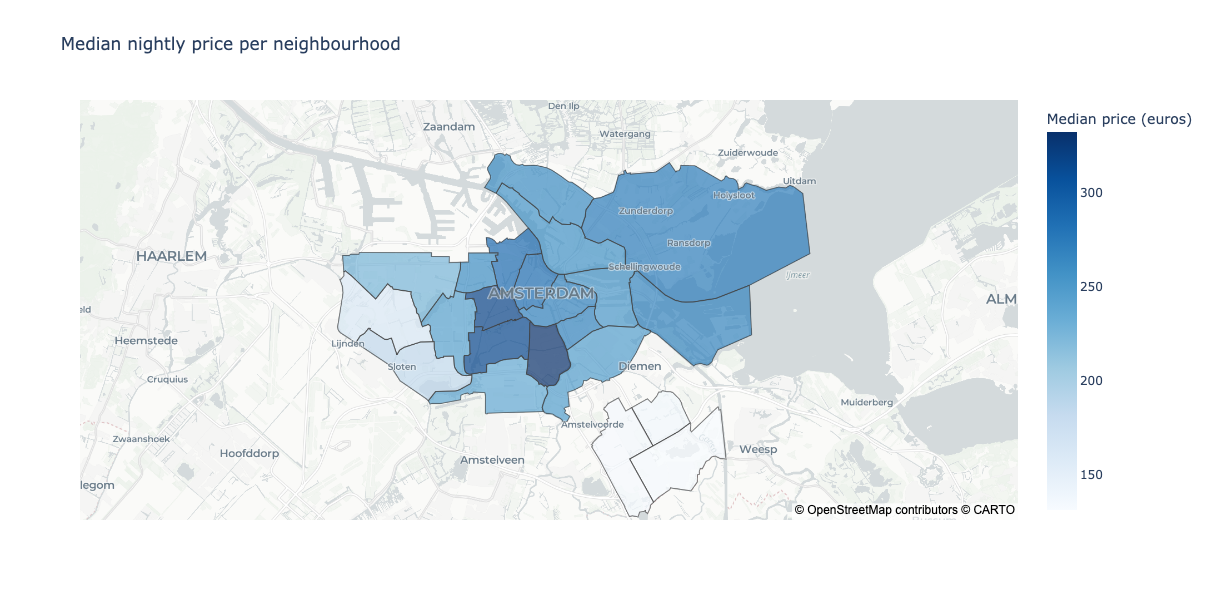

In [43]:
# The polygons as a GeoJSON dictionary, which is the format Plotly wants
neighbourhoods_geojson = json.loads(neighbourhoods.to_json())

MAP_CENTER = {"lat": 52.365, "lon": 4.90}

fig = px.choropleth_map(
    nb_stats,
    geojson=neighbourhoods_geojson,
    locations="neighbourhood",
    featureidkey="properties.neighbourhood",
    color="median_price",
    color_continuous_scale="Blues",
    hover_data=["listings", "median_dist_km"],
    labels={"median_price": "Median price (euros)", "median_dist_km": "Median distance to Dam (km)"},
    map_style="carto-positron",
    center=MAP_CENTER,
    zoom=10,
    opacity=0.7,
    title="Median nightly price per neighbourhood",
    height=600,
)
fig.show()

The cheapest neighbourhoods are at the edge of the city: the south-east (Bijlmer, Gaasperdam) and the far west (Osdorp, De Aker).

The centre is **not** the most expensive area on this map. De Pijp, De Baarsjes - Oud-West and Zuid have a higher median price than Centrum-West and Centrum-Oost.

In [44]:
# share of each room type, for the centre and for the three neighbourhoods with the highest median price
room_mix = pd.crosstab(listings_geo["neighbourhood"], listings_geo["room_type"], normalize="index").round(2)
room_mix.loc[["Centrum-West", "Centrum-Oost", "De Pijp - Rivierenbuurt", "De Baarsjes - Oud-West", "Zuid"]]

room_type,Entire home/apt,Hotel room,Private room,Shared room
neighbourhood,,,,
Centrum-West,0.51,0.0,0.49,0.00
Centrum-Oost,0.54,0.0,0.44,0.01
De Pijp - Rivierenbuurt,0.82,0.0,0.18,0.00
De Baarsjes - Oud-West,0.82,0.0,0.18,0.00
Zuid,0.75,0.0,0.24,0.00


In [49]:
# median price of entire homes only
entire_homes = listings_geo[listings_geo["room_type"] == "Entire home/apt"]
entire_homes.groupby("neighbourhood")["price"].median().sort_values(ascending=False).head(6)

neighbourhood
Centrum-West               393.000
De Pijp - Rivierenbuurt    372.500
Centrum-Oost               366.500
Zuid                       361.625
De Baarsjes - Oud-West     354.000
Watergraafsmeer            344.165
Name: price, dtype: float64

In the centre only about half of the listings are entire homes. The rest are private rooms and hotel rooms, which are cheaper. In De Pijp and De Baarsjes more than 80% are entire homes.

When using the same kind of listings (entire homes) only, Centrum-West is the most expensive neighbourhood.


In [50]:
fig = px.scatter_map(
    listings_geo,
    lat="latitude",
    lon="longitude",
    color="price",
    color_continuous_scale="Viridis",
    range_color=[50, 600],
    hover_name="neighbourhood",
    hover_data=["room_type", "accommodates", "dist_to_dam_km"],
    labels={"price": "Price (euros)", "dist_to_dam_km": "Distance to Dam (km)"},
    map_style="carto-positron",
    center=MAP_CENTER,
    zoom=10.5,
    opacity=0.6,
    title="Listings coloured by nightly price",
    height=650,
)
fig.show()

### 4.2 Price against distance to Dam Square

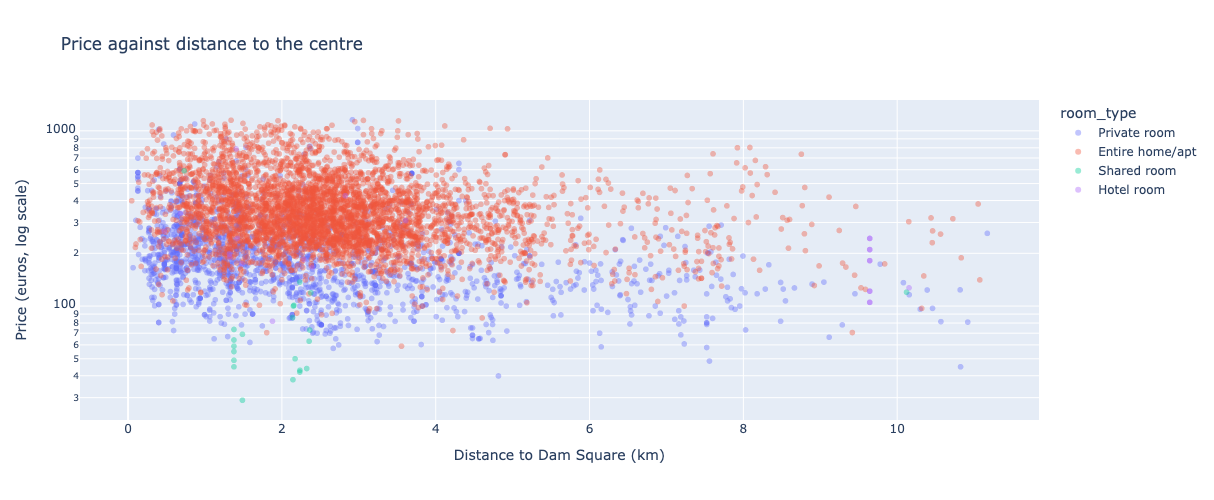

In [45]:
fig = px.scatter(
    listings_geo,
    x="dist_to_dam_km",
    y="price",
    color="room_type",
    opacity=0.4,
    log_y=True,
    hover_data=["neighbourhood", "accommodates"],
    labels={"dist_to_dam_km": "Distance to Dam Square (km)", "price": "Price (euros, log scale)"},
    title="Price against distance to the centre",
    height=500,
)
fig.show()
# should fit a trend line

In [46]:
bands = pd.cut(listings_geo["dist_to_dam_km"], bins=[0, 1, 2, 3, 4, 6, 12])
listings_geo.groupby(bands, observed=True)["price"].agg(["count", "median"]).round(1)

,count,median
dist_to_dam_km,,
"(0, 1]",808,280.5
"(1, 2]",1487,300.0
"(2, 3]",1798,299.5
"(3, 4]",994,279.7
"(4, 6]",589,251.7
"(6, 12]",300,175.4


In [47]:
# plit by the two main room types
main_types = listings_geo[listings_geo["room_type"].isin(["Entire home/apt", "Private room"])]
main_types.groupby([bands, "room_type"], observed=True)["price"].median().unstack().round(1)

room_type,Entire home/apt,Private room
dist_to_dam_km,,
"(0, 1]",394.0,218.0
"(1, 2]",359.6,195.0
"(2, 3]",330.7,157.8
"(3, 4]",301.3,156.6
"(4, 6]",292.0,139.0
"(6, 12]",253.4,128.0


For all listings together, the median price hardly changes in the first 4 km. It only drops clearly after that. This is the same mix effect as on the map: close to Dam Square there are many private rooms.

Within one room type the pattern is clear. Entire homes and private rooms both get cheaper with every step away from Dam Square.

The cloud of dots is also wide: at any distance there are cheap and expensive listings, indicating while distance says something about the price, it does not answer entirely.

## 5. Correlation analysis


In [49]:
df_corr = listings_geo.select_dtypes("number").drop(columns="id")
df_corr["log_price"] = np.log(df_corr["price"])

corr = df_corr.corr()

# correlation of every column with log(price), strongest first
corr["log_price"].drop(["price", "log_price"]).sort_values(key=abs, ascending=False).round(2)

/var/folders/pr/w8zlwczs7471f6bbm6q9mw8c0000gn/T/ipykernel_90438/1153139656.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_corr["log_price"] = np.log(df_corr["price"])


bedrooms                          0.49
accommodates                      0.45
bathroom_shared                  -0.36
reviews_per_month                -0.32
bathrooms                         0.32
beds                              0.30
number_of_reviews                -0.30
amenities_count                   0.27
calculated_host_listings_count   -0.25
review_scores_rating              0.22
dist_to_dam_km                   -0.19
host_is_superhost                -0.17
availability_365                  0.06
minimum_nights                   -0.06
longitude                        -0.05
has_reviews                      -0.04
hosts_time_as_host_years         -0.04
latitude                          0.01
Name: log_price, dtype: float64

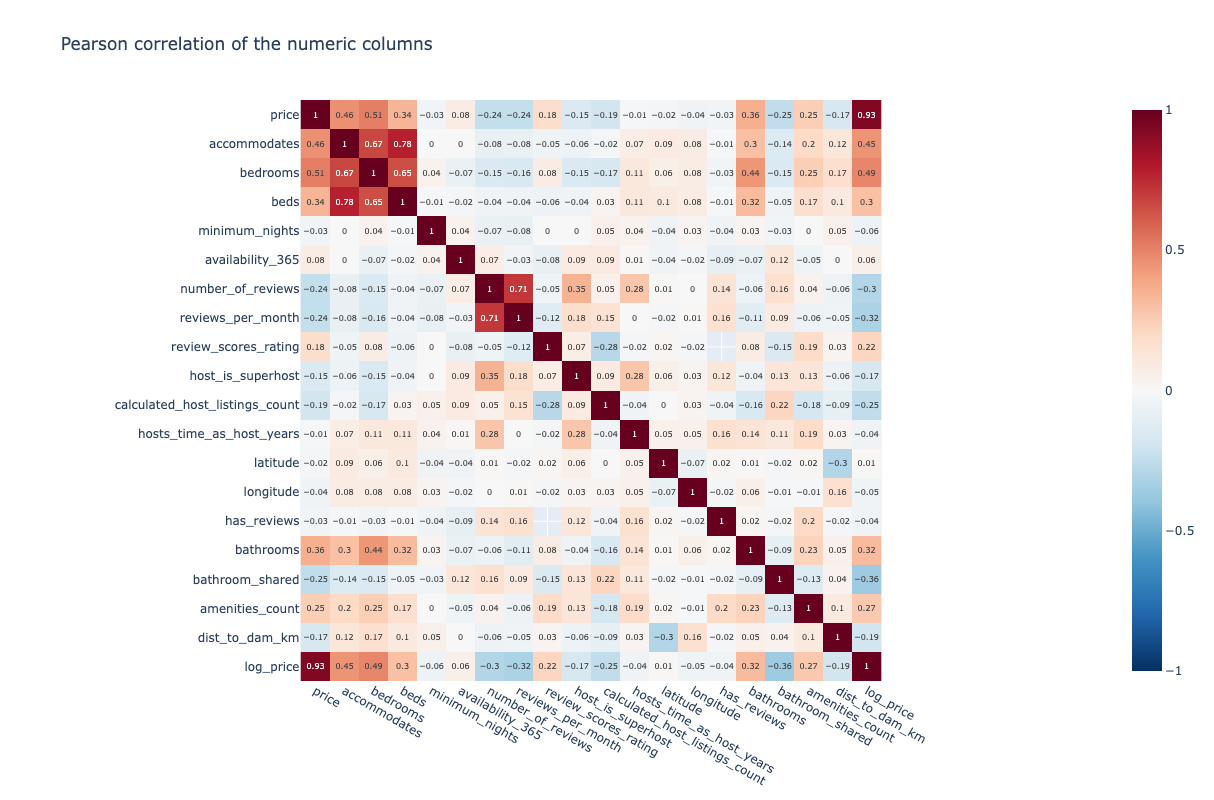

In [50]:
#the correlation between any two columns
fig = px.imshow(
    corr.round(2),
    text_auto=True,
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Pearson correlation of the numeric columns",
    height=800,
    width=900,
)
fig.show()

- The size of the listing has the strongest link with price: `bedrooms` (0.49) and `accommodates` (0.45). These columns are also strongly correlated with each other, which makes sense.
- A shared bathroom goes with a lower price (-0.36).
- Listings with more reviews are cheaper (about -0.3). Cheap rooms are booked more often, so they collect more reviews.
- `dist_to_dam_km` has a weak negative correlation with price (-0.19): further from the centre is cheaper.


## 6. Export the data

In [56]:
listings_geo.drop(columns="geometry").to_csv(CLEAN_PATH, index=False)

print("Saved", listings_geo.shape[0], "rows to", CLEAN_PATH)

Saved 5976 rows to data/listings_clean.csv


## 7. Build the model: basic vs location-enhanced

### 7.1 Two feature sets

- **basic**: the listing, its reviews and its host, excluding any location columns
- **location-enhanced**: basic + neighbourhood + distance to Dam Square + latitude and longitude.


In [52]:
basic_numeric = [
    "accommodates", "bedrooms", "beds", "bathrooms", "bathroom_shared", "amenities_count",
    "minimum_nights", "availability_365",
    "number_of_reviews", "reviews_per_month", "has_reviews", "review_scores_rating",
    "host_is_superhost", "calculated_host_listings_count", "hosts_time_as_host_years",
]
basic_categorical = ["room_type", "property_type"]

location_numeric = ["dist_to_dam_km", "latitude", "longitude"]
location_categorical = ["neighbourhood"]

In [53]:
#one hot encoding

X_basic = pd.get_dummies(
    listings_geo[basic_numeric + basic_categorical],
    columns=basic_categorical,
    dtype=int,
)

X_location = pd.get_dummies(
    listings_geo[basic_numeric + basic_categorical + location_numeric + location_categorical],
    columns=basic_categorical + location_categorical,
    dtype=int,
)

y = listings_geo["price"]

print("basic:            ", X_basic.shape)
print("location-enhanced:", X_location.shape)
print("Same rows in both sets:", X_basic.index.equals(X_location.index))

basic:             (5976, 41)
location-enhanced: (5976, 66)
Same rows in both sets: True


### 7.2 Cross-validation

I will be using XGBoost, without any tuning.

5-fold cross-validation

The model trains on log(price), which then converts each prediction back into euros before the error is measured. RMSE and MAE are in euros.

In [54]:
kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)


def cross_validate_price(X, y):
    rmse_per_fold = []
    mae_per_fold = []
    predictions = pd.Series(np.nan, index=y.index)

    for train_rows, test_rows in kfold.split(X):
        model = XGBRegressor(random_state=SEED)

        # Train on log(price)
        model.fit(X.iloc[train_rows], np.log(y.iloc[train_rows]))

        # Predict, and turn log(price) back into euros
        predicted_price = np.exp(model.predict(X.iloc[test_rows]))
        predictions.iloc[test_rows] = predicted_price

        rmse_per_fold.append(root_mean_squared_error(y.iloc[test_rows], predicted_price))
        mae_per_fold.append(mean_absolute_error(y.iloc[test_rows], predicted_price))

    return np.array(rmse_per_fold), np.array(mae_per_fold), predictions

In [55]:
rmse_basic, mae_basic, pred_basic = cross_validate_price(X_basic, y)
rmse_location, mae_location, pred_location = cross_validate_price(X_location, y)

print("basic              RMSE per fold:", rmse_basic.round(1))
print("location-enhanced  RMSE per fold:", rmse_location.round(1))

basic              RMSE per fold: [134.6 127.9 125.3 131.5 135. ]
location-enhanced  RMSE per fold: [119.9 114.6 110.7 116.  109. ]


## 8. Results

### 8.1 Basic vs location-enhanced

In [56]:
results = pd.DataFrame(
    {
        "features": [X_basic.shape[1], X_location.shape[1]],
        "RMSE (euros)": [rmse_basic.mean(), rmse_location.mean()],
        "RMSE std": [rmse_basic.std(), rmse_location.std()],
        "MAE (euros)": [mae_basic.mean(), mae_location.mean()],
        "MAE std": [mae_basic.std(), mae_location.std()],
    },
    index=["basic", "location-enhanced"],
).round(1)

results

,features,RMSE (euros),RMSE std,MAE (euros),MAE std
basic,41,130.9,3.8,88.7,1.8
location-enhanced,66,114.0,3.9,76.0,2.3


In [57]:
rmse_change = (rmse_location.mean() - rmse_basic.mean()) / rmse_basic.mean() * 100
mae_change = (mae_location.mean() - mae_basic.mean()) / mae_basic.mean() * 100

print("Change in RMSE with location features: {0:.1f}%".format(rmse_change))
print("Change in MAE with location features:  {0:.1f}%".format(mae_change))
print("Median price, for scale: {0:.0f} euros".format(y.median()))

Change in RMSE with location features: -12.9%
Change in MAE with location features:  -14.2%
Median price, for scale: 284 euros


In [58]:
folds = pd.DataFrame(
    {
        "RMSE basic": rmse_basic,
        "RMSE location": rmse_location,
        "MAE basic": mae_basic,
        "MAE location": mae_location,
    },
    index=["fold 1", "fold 2", "fold 3", "fold 4", "fold 5"],
).round(1)

folds

,RMSE basic,RMSE location,MAE basic,MAE location
fold 1,134.6,119.9,90.0,80.0
fold 2,127.9,114.6,88.0,75.5
fold 3,125.3,110.7,85.9,73.7
fold 4,131.5,116.0,88.4,76.7
fold 5,135.0,109.0,91.1,74.3


The location features improve the predictions:

- RMSE drops from about 131 to about 114 euros (about 13% lower).
- MAE drops from about 89 to about 76 euros (about 14% lower).
- The location-enhanced model is better in **all 5 folds**. The gain (about 17 euros of RMSE) is much larger than the spread between folds (about 4 euros).

The errors are still large. The median price is 284 euros, so the location-enhanced model is off by about a quarter of a typical price. RMSE is higher than MAE because it punishes large errors more, and expensive listings are hard to predict.

### 8.2 Which features does the location-enhanced model use?

Feature importance

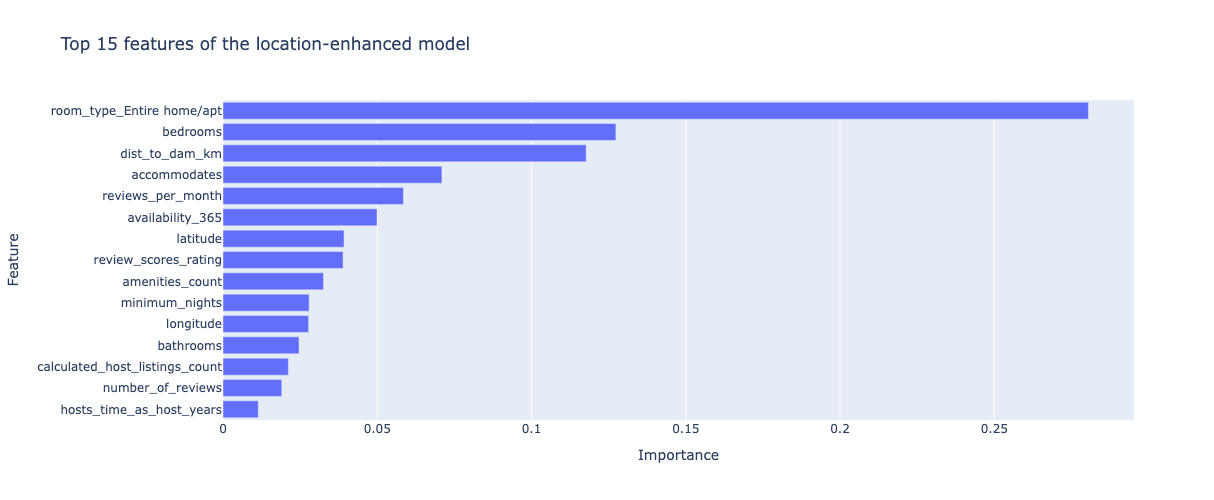

In [61]:
model = XGBRegressor(random_state=SEED, importance_type='total_gain')
model.fit(X_location, np.log(y))

importance = pd.Series(model.feature_importances_, index=X_location.columns).sort_values()

fig = px.bar(
    importance.tail(15),
    orientation="h",
    labels={"value": "Importance", "index": "Feature"},
    title="Top 15 features of the location-enhanced model",
    height=500,
)
fig.update_layout(showlegend=False)
fig.show()

In [62]:
# all columns that are in the location-enhanced set but not in the basic set
location_columns = [col for col in X_location.columns if col not in X_basic.columns]

print("Number of location columns:", len(location_columns))
print("Share of the importance from location columns:", round(importance[location_columns].sum(), 3))

Number of location columns: 25
Share of the importance from location columns: 0.197


What I see:

- "Entire home or not" has about 28% of the importance, the largest single column.
- Distance to Dam Square is next. "dist_to_dam_km" has about 12% on its own, the strongest location column by far.
- 
The 25 location columns have about 20% of the importance. Most of it comes from distance (12%) and the coordinates (about 4% for latitude and 3% for longitude). The 22 neighbourhood columns add only about 1%.


### 8.3 Map of the model errors per neighbourhood

In [63]:
errors = pd.DataFrame(
    {
        "neighbourhood": listings_geo["neighbourhood"],
        "mae_basic": (y - pred_basic).abs(),
        "mae_location": (y - pred_location).abs(),
    }
)

nb_errors = errors.groupby("neighbourhood").mean()
nb_errors["improvement"] = nb_errors["mae_basic"] - nb_errors["mae_location"]
nb_errors["listings"] = errors.groupby("neighbourhood").size()
nb_errors = nb_errors.round(1).reset_index().sort_values("improvement", ascending=False)

nb_errors

/var/folders/pr/w8zlwczs7471f6bbm6q9mw8c0000gn/T/ipykernel_90438/4003047925.py:10: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  nb_errors["improvement"] = nb_errors["mae_basic"] - nb_errors["mae_location"]
/var/folders/pr/w8zlwczs7471f6bbm6

,neighbourhood,mae_basic,mae_location,improvement,listings
13,Noord-West,97.2,50.6,46.6,173
15,Osdorp,77.7,35.7,42.1,41
12,Noord-Oost,97.3,61.7,35.6,114
9,Gaasperdam - Driemond,72.8,40.9,31.9,34
10,Geuzenveld - Slotermeer,89.5,60.3,29.3,96
16,Oud-Noord,85.5,62.9,22.6,260
18,Slotervaart,73.1,55.1,18.0,102
1,Bijlmer-Oost,63.2,45.6,17.6,24
0,Bijlmer-Centrum,49.2,33.3,15.9,42
5,Centrum-West,97.3,82.1,15.3,836


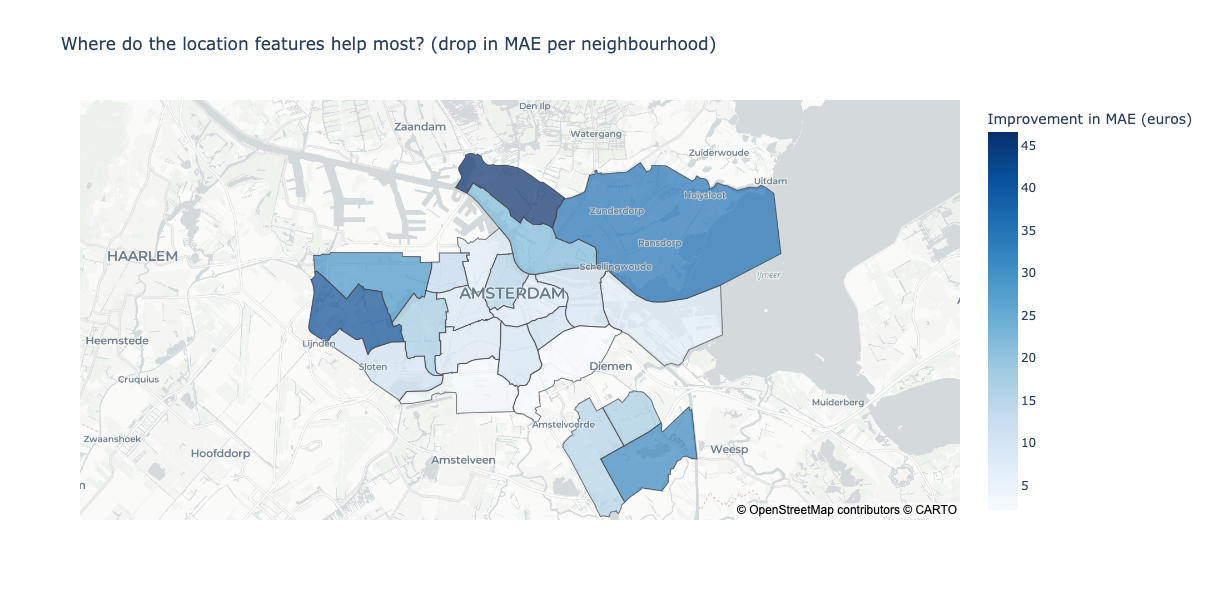

In [64]:
fig = px.choropleth_map(
    nb_errors,
    geojson=neighbourhoods_geojson,
    locations="neighbourhood",
    featureidkey="properties.neighbourhood",
    color="improvement",
    color_continuous_scale="Blues",
    hover_data=["mae_basic", "mae_location", "listings"],
    labels={
        "improvement": "Improvement in MAE (euros)",
        "mae_basic": "MAE basic (euros)",
        "mae_location": "MAE location (euros)",
    },
    map_style="carto-positron",
    center=MAP_CENTER,
    zoom=10,
    opacity=0.7,
    title="Where do the location features help most? (drop in MAE per neighbourhood)",
    height=600,
)
fig.show()

The location features lower the error in every neighbourhood, but not by the same amount.

- The gain is largest outside the centre: Noord-West, Osdorp, Noord-Oost, Gaasperdam - Driemond and Geuzenveld - Slotermeer. In Noord-West the error almost halves (from about 97 to about 51 euros).
- The gain is small in neighbourhoods such as Watergraafsmeer, Buitenveldert - Zuidas and Westerpark, and modest in the centre.

## 9. Conclusion

**Answer to the research question.** Yes. Location features improve the price predictions for Amsterdam Airbnb listings. With the same model, the same rows and the same folds, adding the neighbourhood, the distance to Dam Square and the coordinates lowers the RMSE from about 131 to about 114 euros (about 13%) and the MAE from about 89 to about 76 euros (about 14%).

- Location matters, but it is not the main driver. The kind of listing (entire home or room, number of bedrooms) explains most of the price.
- Raw averages per neighbourhood are misleading. The centre looks cheaper than De Pijp, only because it has more private rooms and hotel rooms. For the same kind of listing the centre is the most expensive.
- The location features help most for listings far from the centre. Without location, the model gives them a central price that is too high.

**Some challenges faced are:**

- **Active listings only.** 43% of the listings have no price, and these are mostly listings that cannot be booked.
- **The price is one quote.** Each price is for one stay on one date, and the dates differ per listing (from September 2026 to September 2027). Season and length of stay add noise.
- **Outliers removed.** I removed listings above about 1,164 euros per night. The model is not tested on the most expensive listings.
- **Coordinates are not exact.** Inside Airbnb shifts each listing by up to about 150 metres for privacy. Distances have a small error.
- **Distance is simple.** I use the straight-line distance to one point. Travel time, or the distance to a station or a canal, could say more.
- **One default model.** No tuning and one set of folds. A tuned model would have smaller errors, but the comparison between the two feature sets was the goal, not the lowest error.
- **The error is still large.** An average error of about 76 euros on a median price of 284 euros is too much for setting a real price.